# Heart Disease Prediction System

**Course:** AIC354 - Artificial Intelligence  
**Project:** Assignment 2 - Heart Disease Prediction  
**Student Name:** Abdul Wahab Siddiqi  
**GitHub Repository:** https://github.com/Ab-Wb-Sid/Heart-Disease-Prediction  
**Streamlit App URL:** Not deployed yet. Add the live URL after Streamlit Community Cloud deployment.

This notebook follows the same beginner-friendly machine-learning workflow as the Titanic survival prediction reference: load data, inspect it, clean it, select features, train a model, evaluate it, save it, and test the saved artifact.

## 1. Import Libraries

We use pandas and numpy for data work, scikit-learn for preprocessing/modeling/evaluation, matplotlib for simple charts, and joblib for saving/loading the trained pipeline.

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "heart+disease" / "processed.cleveland.data"
CLEAN_DATA_PATH = PROJECT_ROOT / "data" / "heart_disease_cleveland_selected.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "heart_disease_pipeline.joblib"
METADATA_PATH = PROJECT_ROOT / "models" / "model_metadata.json"

FEATURES = ["age", "cp", "thalach", "oldpeak"]
TARGET_SOURCE = "num"
TARGET = "target"

ALL_COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

## 2. Load the UCI Heart Disease Dataset

The downloaded UCI folder contains several variants. I use `heart+disease/processed.cleveland.data` because the UCI documentation says the Cleveland database is the processed variant most commonly used in ML experiments. The file is comma-separated and has no header row, so we provide the documented 14 column names manually. Question marks are treated as missing values.

In [2]:
raw_df = pd.read_csv(DATA_PATH, names=ALL_COLUMNS, na_values="?")
print(f"Rows: {raw_df.shape[0]}, Columns: {raw_df.shape[1]}")
raw_df.head()

Rows: 303, Columns: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 3. Inspect Schema, Statistics, Class Balance, and Missing Values

In [3]:
print("Column data types:")
print(raw_df.dtypes)

print("\nDescriptive statistics:")
display(raw_df.describe().T)

print("\nOriginal num target distribution:")
print(raw_df["num"].value_counts().sort_index())

print("\nMissing values after converting '?' to NaN:")
print(raw_df.isna().sum())

Column data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Original num target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Missing values after converting '?' to NaN:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


## 4. Select the Required Four Attributes

The assignment requires exactly four input attributes:

- `age`: age in years.
- `cp`: chest pain type. UCI codes are 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic.
- `thalach`: maximum heart rate achieved.
- `oldpeak`: ST depression induced by exercise relative to rest.

The target comes from `num`: `0` means no disease, while values greater than `0` mean disease is present.

In [4]:
selected_df = raw_df[FEATURES + [TARGET_SOURCE]].copy()
selected_df[TARGET] = (selected_df[TARGET_SOURCE] > 0).astype(int)

print(selected_df.head())
print("\nSelected-column missing values:")
print(selected_df.isna().sum())
print("\nBinary target distribution:")
print(selected_df[TARGET].value_counts().sort_index())

selected_df.to_csv(CLEAN_DATA_PATH, index=False)
print(f"Saved clean selected dataset to: {CLEAN_DATA_PATH}")

    age   cp  thalach  oldpeak  num  target
0  63.0  1.0    150.0      2.3    0       0
1  67.0  4.0    108.0      1.5    2       1
2  67.0  4.0    129.0      2.6    1       1
3  37.0  3.0    187.0      3.5    0       0
4  41.0  2.0    172.0      1.4    0       0

Selected-column missing values:
age        0
cp         0
thalach    0
oldpeak    0
num        0
target     0
dtype: int64

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64
Saved clean selected dataset to: C:\Users\X1 Nano\Desktop\Git Local Repos\Heart-Disease-Prediction\data\heart_disease_cleveland_selected.csv


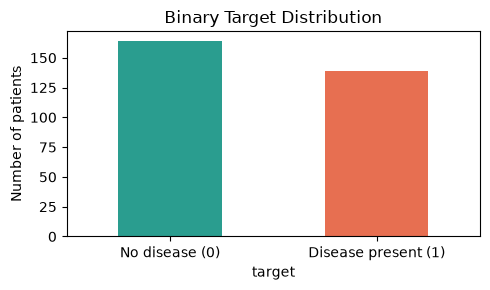

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
selected_df[TARGET].value_counts().sort_index().plot(kind="bar", ax=ax, color=["#2a9d8f", "#e76f51"])
ax.set_xticklabels(["No disease (0)", "Disease present (1)"], rotation=0)
ax.set_ylabel("Number of patients")
ax.set_title("Binary Target Distribution")
plt.tight_layout()
plt.show()

## 5. Split Data Before Fitting Preprocessing

To avoid data leakage, the train/test split happens before fitting imputers, scalers, encoders, or the model. The complete scikit-learn `Pipeline` learns preprocessing only from the training data.

In [6]:
X = selected_df[FEATURES]
y = selected_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Features used:", list(X_train.columns))

Training rows: 242
Testing rows: 61
Features used: ['age', 'cp', 'thalach', 'oldpeak']


## 6. Build and Train the Model Pipeline

`cp` is a categorical code, so it is one-hot encoded. The other three fields are numeric and are imputed with the median, then standardized. Logistic regression is a suitable beginner-friendly binary classifier for this assignment.

In [7]:
numeric_features = ["age", "thalach", "oldpeak"]
categorical_features = ["cp"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("categorical", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ],
    remainder="drop",
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

model_pipeline.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## 7. Evaluate the Model

These metrics are calculated from the held-out test set. They are not fabricated; they come from the actual split produced by the random seed above.

Accuracy : 0.852
Precision: 0.913
Recall   : 0.750
F1-score : 0.824

Classification report:
                 precision    recall  f1-score   support

     No disease       0.82      0.94      0.87        33
Disease present       0.91      0.75      0.82        28

       accuracy                           0.85        61
      macro avg       0.86      0.84      0.85        61
   weighted avg       0.86      0.85      0.85        61



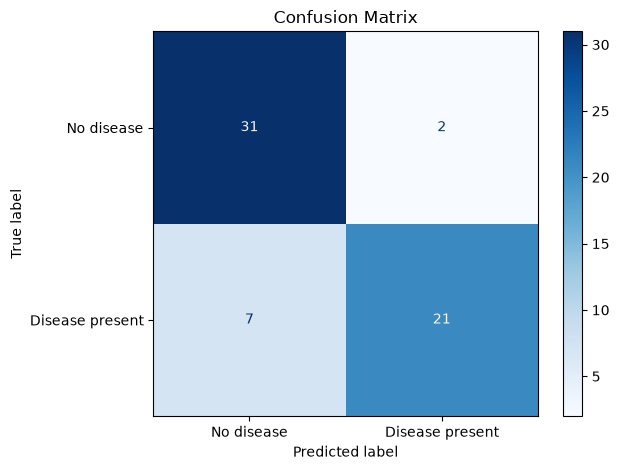

In [8]:
y_pred = model_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease present"], zero_division=0))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No disease", "Disease present"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Save the Complete Fitted Pipeline

Saving the complete fitted pipeline is important because it preserves the preprocessing steps and the trained classifier together. The Streamlit app uses this saved artifact and does not retrain on startup.

In [9]:
joblib.dump(model_pipeline, MODEL_PATH)

metadata = {
    "source_file": str(DATA_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "clean_data_file": str(CLEAN_DATA_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "model_file": str(MODEL_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "selected_dataset_variant": "processed.cleveland.data",
    "features": FEATURES,
    "target_source": TARGET_SOURCE,
    "target_rule": "target = 0 when num == 0, otherwise target = 1 when num > 0",
    "feature_ranges": {feature: {"min": float(selected_df[feature].min()), "max": float(selected_df[feature].max())} for feature in FEATURES},
    "cp_values": sorted(float(value) for value in selected_df["cp"].dropna().unique()),
    "rows": int(selected_df.shape[0]),
    "missing_values": selected_df.isna().sum().astype(int).to_dict(),
    "class_distribution": selected_df[TARGET].value_counts().sort_index().astype(int).to_dict(),
    "metrics": {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "confusion_matrix": cm.tolist(),
    },
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved model to: {MODEL_PATH}")
print(f"Saved metadata to: {METADATA_PATH}")

Saved model to: C:\Users\X1 Nano\Desktop\Git Local Repos\Heart-Disease-Prediction\models\heart_disease_pipeline.joblib
Saved metadata to: C:\Users\X1 Nano\Desktop\Git Local Repos\Heart-Disease-Prediction\models\model_metadata.json


## 9. Load the Saved Artifact and Make a Prediction

This checks that the saved file can be loaded later by `app.py` and used with the same four feature columns in the same order.

In [10]:
loaded_pipeline = joblib.load(MODEL_PATH)
sample_patient = pd.DataFrame([{
    "age": 55,
    "cp": 4,
    "thalach": 150,
    "oldpeak": 1.5,
}], columns=FEATURES)

prediction = loaded_pipeline.predict(sample_patient)[0]
probability = loaded_pipeline.predict_proba(sample_patient)[0]
print("Sample patient input:")
display(sample_patient)
print("Prediction:", "Disease present" if prediction == 1 else "No disease")
print(f"Probability of no disease: {probability[0]:.3f}")
print(f"Probability of disease present: {probability[1]:.3f}")

Sample patient input:


,age,cp,thalach,oldpeak
0,55,4,150,1.5


Prediction: Disease present
Probability of no disease: 0.271
Probability of disease present: 0.729


## 10. Limitations

This is an educational machine-learning project, not a medical diagnosis tool. The model uses only four attributes from an older dataset, so it cannot represent the full complexity of real clinical decision making. Results should be interpreted as a classroom demonstration of data processing, model training, evaluation, saving, and deployment workflow.